# Klasifikasi Huruf BISINDO Berbasis Landmark Tangan
### Perbandingan SVM, Random Forest, dan KNN dengan fitur MediaPipe Hands

Notebook ini berisi **Bagian 1 (Preprocessing & Ekstraksi Fitur)** dan **Bagian 2 (Training, Tuning, & Evaluasi)**.

**Alur:**
1. Eksplorasi dataset citra BISINDO (A–Z)
2. Deteksi 21 landmark per tangan dengan MediaPipe Hands (maks. 2 tangan)
3. Normalisasi koordinat relatif terhadap pergelangan tangan (*wrist*) → vektor 126 fitur
4. Stratified train-test split 80:20 + StandardScaler
5. GridSearchCV 5-fold untuk SVM, Random Forest, KNN
6. Evaluasi: accuracy, precision, recall, macro F1, confusion matrix
7. Menyimpan model terbaik (model + scaler + label encoder) dengan joblib untuk backend FastAPI

## 0. Setup & Konfigurasi

In [42]:
#%pip install mediapipe opencv-python numpy pandas scikit-learn joblib matplotlib tqdm

In [43]:
import os
os.environ.setdefault("GLOG_minloglevel", "2")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import json
import random
import time
import urllib.request
import warnings
from datetime import datetime
from pathlib import Path

import cv2
import joblib
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100
print("mediapipe", mp.__version__)

mediapipe 1.2.3


In [44]:
# Path
ROOT_DIR = Path.cwd()
DATASET_DIR = ROOT_DIR.parent / "bisindo" / "images"
DATA_DIR, MODELS_DIR, REPORTS_DIR = ROOT_DIR / "data", ROOT_DIR / "models", ROOT_DIR / "reports"
for d in (DATA_DIR, MODELS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

FEATURES_CSV = DATA_DIR / "landmarks.csv"
HAND_MODEL_PATH = MODELS_DIR / "hand_landmarker.task"
HAND_MODEL_URL = ("https://storage.googleapis.com/mediapipe-models/hand_landmarker/"
                  "hand_landmarker/float16/latest/hand_landmarker.task")

# Fitur
NUM_LANDMARKS, MAX_HANDS = 21, 2
FEATURES_PER_HAND = NUM_LANDMARKS * 3
NUM_FEATURES = FEATURES_PER_HAND * MAX_HANDS 
FEATURE_COLUMNS = [f"h{h}_p{p}_{c}" for h in range(MAX_HANDS)
                   for p in range(NUM_LANDMARKS) for c in "xyz"]
MIN_CONF = 0.3

# Eksperimen
RANDOM_STATE, TEST_SIZE, CV_FOLDS, SCORING = 42, 0.20, 5, "f1_macro"
REUSE_FEATURES = True
LIMIT_PER_CLASS = None
QUICK_GRID = False
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Dataset :", DATASET_DIR, "| ada:", DATASET_DIR.exists())

Dataset : d:\KULYAH\SEM5\ML\PROJECT BISINDO\bisindo\images | ada: True


## 1. Eksplorasi Dataset
Dataset berisi folder train dan val, masing-masing dengan subfolder per huruf. Sesuai rancangan penelitian, kedua folder digabung lalu dibagi ulang secara stratified 80:20.

In [45]:
def list_images(dataset_dir, limit=None):
    """Kembalikan list (path, split_asal, label)."""
    items = []
    split_dirs = sorted(d for d in dataset_dir.iterdir() if d.is_dir())
    if all(len(d.name) == 1 for d in split_dirs):
        split_dirs = [dataset_dir]
    for split_dir in split_dirs:
        split = "all" if split_dir == dataset_dir else split_dir.name
        for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
            files = sorted(f for f in class_dir.iterdir() if f.suffix.lower() in IMAGE_EXTS)
            if limit and len(files) > limit:
                files = sorted(random.Random(RANDOM_STATE).sample(files, limit))
            items += [(f, split, class_dir.name.upper()) for f in files]
    return items

items = list_images(DATASET_DIR, LIMIT_PER_CLASS)
df_files = pd.DataFrame(items, columns=["path", "split", "label"])
df_files["prefix"] = df_files["path"].map(lambda p: "".join(c for c in p.stem.split("_")[0].split(" ")[0] if c.isalpha()) or "lainnya")
print(f"Total gambar: {len(df_files)}")
pd.crosstab(df_files["label"], df_files["split"], margins=True).T

Total gambar: 11470


label,A,B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,R,S,T,U,V,W,X,Y,Z,All
split,,,,,,,,,,,,,,,,,,,,,,,,,,,
train,350,351,343,348,352,357,360,348,360,360,348,357,355,350,357,357,348,350,343,360,355,357,360,355,328,360,9169
val,88,88,86,87,89,90,90,87,90,90,87,90,89,88,90,90,87,88,86,90,89,90,90,89,83,90,2301
All,438,439,429,435,441,447,450,435,450,450,435,447,444,438,447,447,435,438,429,450,444,447,450,444,411,450,11470


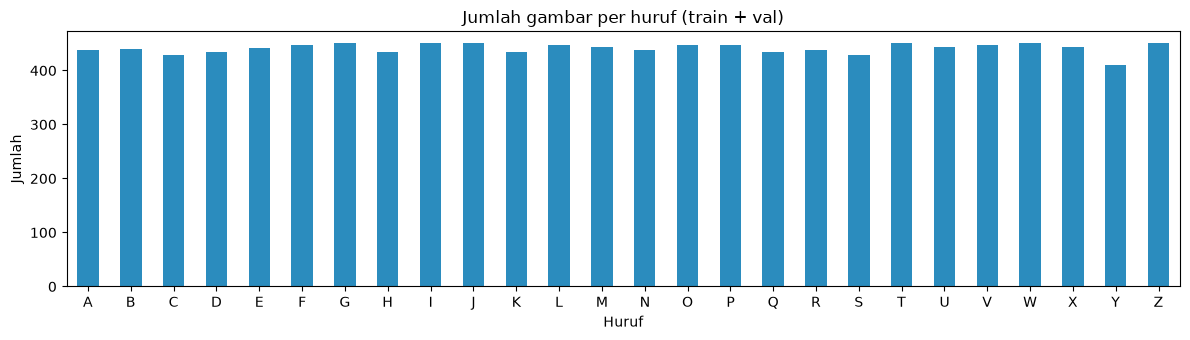

Jenis file berdasarkan nama (indikasi augmentasi):
prefix
flip         3826
rotate       3822
augmented    2425
image         915
body          192
imagep        103
wall           96
IMG            74
imagee         15
lainnya         2


In [46]:
fig, ax = plt.subplots(figsize=(12, 3.5))
df_files["label"].value_counts().sort_index().plot.bar(ax=ax, color="#2b8cbe")
ax.set_title("Jumlah gambar per huruf (train + val)")
ax.set_xlabel("Huruf"); ax.set_ylabel("Jumlah"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

print("Jenis file berdasarkan nama (indikasi augmentasi):")
print(df_files["prefix"].value_counts().to_string())

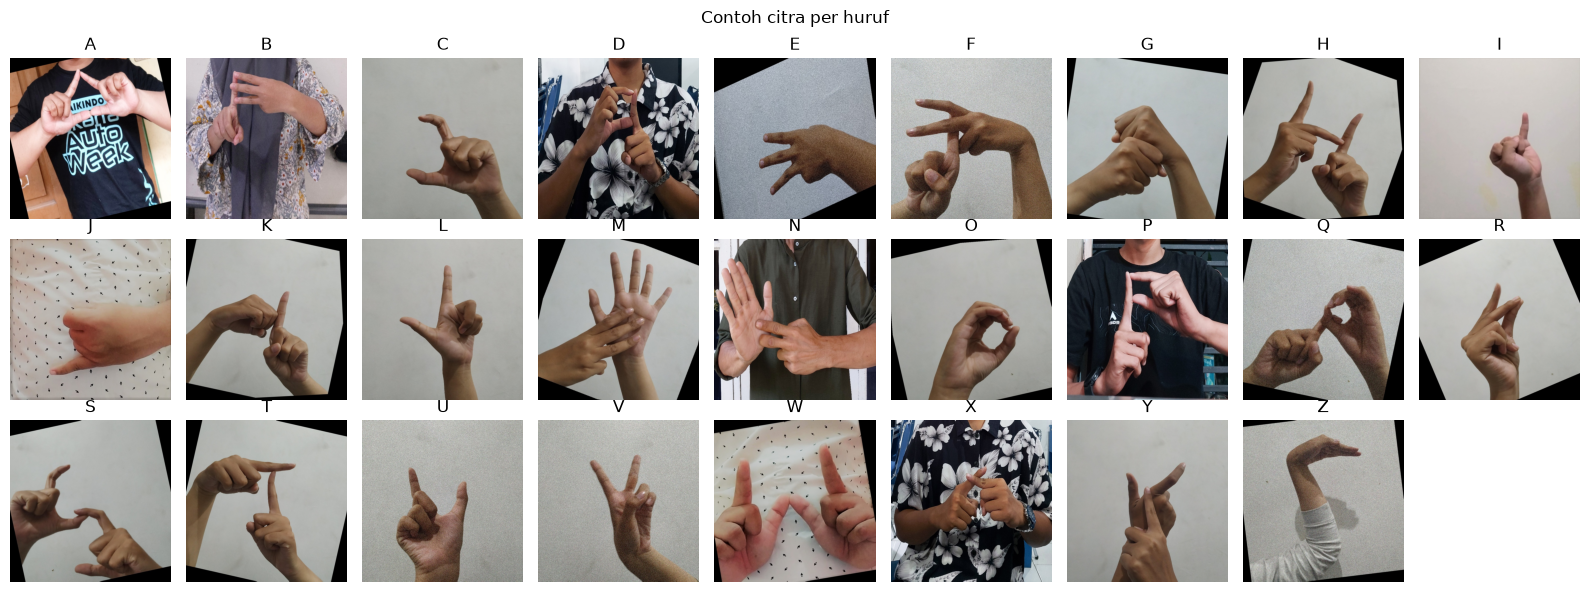

In [47]:
def read_image(path):
    """Baca gambar aman untuk path Windows berspasi/unicode."""
    data = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(data, cv2.IMREAD_COLOR) if data.size else None

# Contoh 1 gambar per huruf
rng = random.Random(0)
fig, axes = plt.subplots(3, 9, figsize=(16, 6))
for ax, letter in zip(axes.flat, sorted(df_files["label"].unique())):
    p = rng.choice(df_files.loc[df_files.label == letter, "path"].tolist())
    ax.imshow(cv2.cvtColor(read_image(p), cv2.COLOR_BGR2RGB)); ax.set_title(letter)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Contoh citra per huruf"); plt.tight_layout(); plt.show()

## 2. Deteksi Landmark dengan MediaPipe Hands
Setiap tangan menghasilkan 21 titik (x, y, z): x dan y ternormalisasi 0–1 terhadap lebar/tinggi gambar, z adalah kedalaman relatif terhadap pergelangan.

In [48]:
if not HAND_MODEL_PATH.exists():
    print("Mengunduh model MediaPipe ...")
    urllib.request.urlretrieve(HAND_MODEL_URL, HAND_MODEL_PATH)

landmarker = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path=str(HAND_MODEL_PATH)),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=MAX_HANDS,
    min_hand_detection_confidence=MIN_CONF,
    min_hand_presence_confidence=MIN_CONF,
))

def detect_hands(image_bgr):
    """Deteksi tangan -> list of (titik_piksel (21,3), handedness, titik_normal (21,3))."""
    h, w = image_bgr.shape[:2]
    rgb = np.ascontiguousarray(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    result = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    hands = []
    for i, lms in enumerate(result.hand_landmarks[:MAX_HANDS]):
        # konversi ke piksel agar rasio aspek tidak terdistorsi; z memakai skala lebar
        pts = np.array([[lm.x * w, lm.y * h, lm.z * w] for lm in lms], dtype=np.float32)
        raw = np.array([[lm.x, lm.y, lm.z] for lm in lms], dtype=np.float32)
        side = result.handedness[i][0].category_name if result.handedness else "?"
        hands.append((pts, side, raw))
    return hands

### 2.1 Masalah: noise pada gambar augmentasi
Pada uji awal, detection rate hanya ±71%. Hampir semua gambar yang gagal adalah augmented_image_*, yang diberi noise bintik berat sehingga detektor telapak MediaPipe gagal.
Solusinya adalah menerapkan median blur sebelum deteksi. Median filter menghapus noise salt-and-pepper tanpa merusak tepi jari.

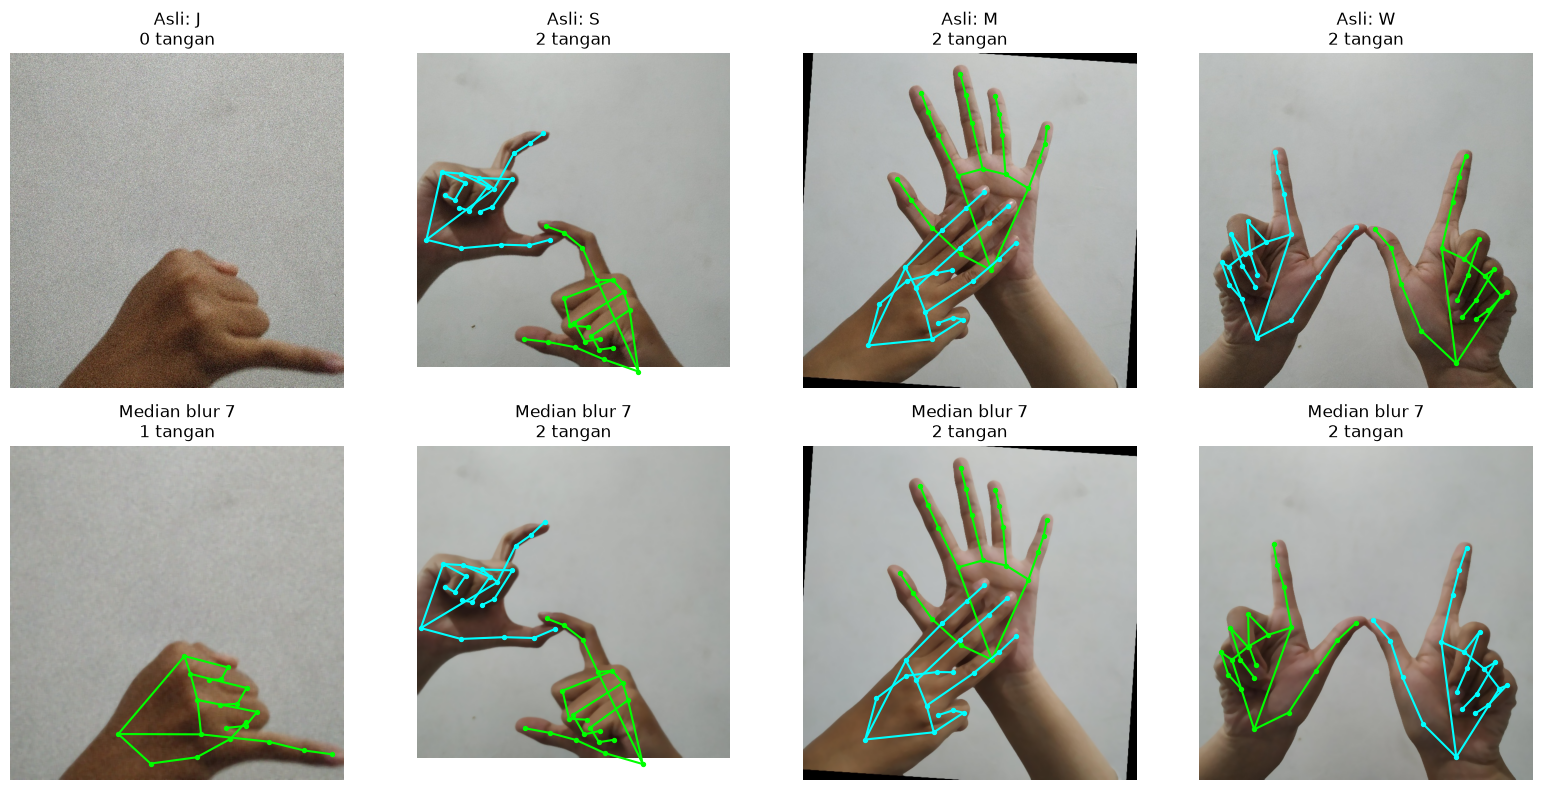

In [49]:
HAND_CONNECTIONS = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
                    (9,13),(13,14),(14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]

def draw_hands(ax, image_bgr, hands, title):
    ax.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    h, w = image_bgr.shape[:2]
    for k, (_, _, raw) in enumerate(hands):
        color = ["lime", "cyan"][k % 2]
        for a, b in HAND_CONNECTIONS:
            ax.plot([raw[a, 0] * w, raw[b, 0] * w], [raw[a, 1] * h, raw[b, 1] * h], color=color, lw=1.5)
        ax.scatter(raw[:, 0] * w, raw[:, 1] * h, s=8, c=color)
    ax.set_title(f"{title}\n{len(hands)} tangan"); ax.axis("off")

# Ambil beberapa gambar augmented_image_* untuk demo
demo = df_files[df_files["prefix"] == "augmented"].sample(4, random_state=1)["path"].tolist()
fig, axes = plt.subplots(2, len(demo), figsize=(4 * len(demo), 8))
for j, p in enumerate(demo):
    img = read_image(p)
    draw_hands(axes[0, j], img, detect_hands(img), f"Asli: {p.parent.name}")
    blur = cv2.medianBlur(img, 7)
    draw_hands(axes[1, j], blur, detect_hands(blur), "Median blur 7")
plt.tight_layout(); plt.show()

Karena satu filter tidak selalu cocok untuk semua gambar, digunakan cascade yaitu beberapa varian dicoba berurutan, kemudian dipilih hasil dengan jumlah tangan terbanyak, dan pencarian berhenti begitu 2 tangan ditemukan.

In [50]:
PREPROCESSORS = {
    "orig":    lambda img: img,
    "median5": lambda img: cv2.medianBlur(img, 5),
    "median7": lambda img: cv2.medianBlur(img, 7),
    "median9": lambda img: cv2.medianBlur(img, 9),
}
DATASET_VARIANTS = ("median7", "orig", "median5", "median9")
REALTIME_VARIANTS = ("median7", "orig")   # dipakai backend (lebih cepat)

def detect_best(image_bgr, variants=DATASET_VARIANTS):
    best, best_name = [], None
    for name in variants:
        hands = detect_hands(PREPROCESSORS[name](image_bgr))
        if best_name is None or len(hands) > len(best):
            best, best_name = hands, name
        if len(best) >= MAX_HANDS:
            break
    return best, best_name

## 3. Normalisasi & Penyusunan Vektor Fitur (126 fitur)

Normalisasi per tangan:
1. Translasi : semua titik dikurangi koordinat wrist (titik 0), sehingga fitur tidak bergantung pada posisi tangan di gambar.
2. Skala: dibagi jarak terjauh titik ke wrist (bidang x-y), sehingga fitur tidak bergantung pada ukuran tangan atau jarak ke kamera.

Penataan dua tangan:
- 2 tangan diurutkan berdasarkan posisi x wrist (tangan paling kiri di gambar = slot 0). Label kiri/kanan MediaPipe tidak dipakai karena tidak stabil pada gambar hasil flip.
- 1 tangan masuk ke slot 0, dan slot 1 diisi nol (zero-padding).

In [51]:
WRIST = 0

def normalize_hand(points):
    rel = points - points[WRIST]
    scale = np.max(np.linalg.norm(rel[:, :2], axis=1))
    return (rel / (scale if scale > 1e-6 else 1.0)).astype(np.float32).flatten()

def build_feature_vector(hands):
    hands = sorted(hands, key=lambda t: t[0][WRIST, 0])
    feat = np.zeros(NUM_FEATURES, dtype=np.float32)
    for slot, (pts, _, _) in enumerate(hands[:MAX_HANDS]):
        feat[slot * FEATURES_PER_HAND:(slot + 1) * FEATURES_PER_HAND] = normalize_hand(pts)
    return feat

def extract_features(image_bgr, variants=DATASET_VARIANTS):
    hands, variant = detect_best(image_bgr, variants)
    return build_feature_vector(hands), len(hands), variant

pts = np.random.default_rng(0).random((21, 3)).astype(np.float32) * 100
print("Invarian posisi & skala:", np.allclose(normalize_hand(pts), normalize_hand(pts * 2.5 + 40), atol=1e-5))

Invarian posisi & skala: True


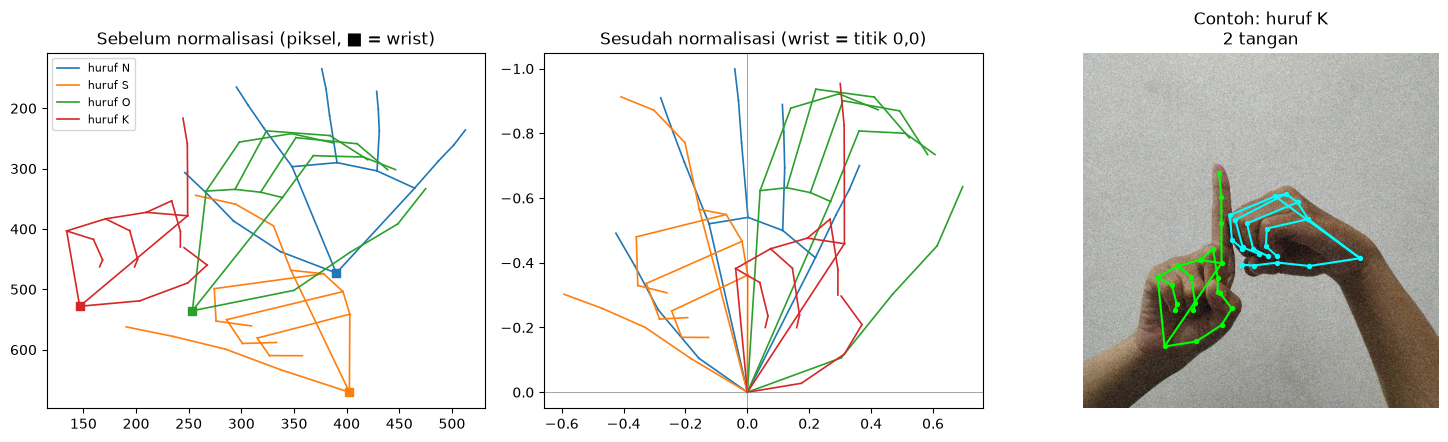

In [52]:
# Visualisasi: koordinat mentah vs setelah normalisasi (beberapa huruf)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sample = df_files.sample(30, random_state=3)["path"].tolist()
shown = 0
for p in sample:
    img = read_image(p)
    hands, _ = detect_best(img)
    if not hands:
        continue
    pts_px = hands[0][0]
    n = normalize_hand(pts_px).reshape(21, 3)
    color = f"C{shown}"
    for k, (a, b) in enumerate(HAND_CONNECTIONS):
        axes[0].plot(pts_px[[a, b], 0], pts_px[[a, b], 1], color=color, lw=1.2,
                     label=f"huruf {p.parent.name}" if k == 0 else None)
        axes[1].plot(n[[a, b], 0], n[[a, b], 1], color=color, lw=1.2)
    axes[0].scatter(pts_px[0, 0], pts_px[0, 1], c=color, marker="s", s=30)
    shown += 1
    if shown == 4:
        draw_hands(axes[2], img, hands, f"Contoh: huruf {p.parent.name}")
        break
axes[0].invert_yaxis(); axes[0].set_title("Sebelum normalisasi (piksel, ■ = wrist)"); axes[0].legend(fontsize=8)
axes[1].invert_yaxis(); axes[1].set_title("Sesudah normalisasi (wrist = titik 0,0)"); axes[1].axhline(0, c="gray", lw=.5); axes[1].axvline(0, c="gray", lw=.5)
plt.tight_layout(); plt.show()

## 4. Ekstraksi Fitur Seluruh Dataset
Setiap gambar diubah menjadi 1 baris berisi 126 fitur. Gambar yang tidak terdeteksi tangannya dicatat dan dibuang. Proses penuh memakan waktu ±25 menit (±8 gambar/detik).

In [15]:
if REUSE_FEATURES and FEATURES_CSV.exists():
    df = pd.read_csv(FEATURES_CSV)
    failed = pd.read_csv(DATA_DIR / "failed_images.csv") if (DATA_DIR / "failed_images.csv").exists() else pd.DataFrame(columns=["path", "label", "reason"])
    print(f"Memakai fitur tersimpan: {FEATURES_CSV} ({len(df)} baris)")
else:
    rows, fails = [], []
    t0 = time.time()
    for path, split, label in tqdm(items, desc="Ekstraksi"):
        img = read_image(path)
        if img is None:
            fails.append({"path": str(path), "label": label, "reason": "gagal_dibaca"}); continue
        feat, n_hands, variant = extract_features(img)
        if n_hands == 0:
            fails.append({"path": str(path), "label": label, "reason": "tangan_tidak_terdeteksi"}); continue
        rows.append({"path": str(path), "source_split": split, "label": label,
                     "num_hands": n_hands, "variant": variant, **dict(zip(FEATURE_COLUMNS, feat.tolist()))})
    df = pd.DataFrame(rows, columns=["path", "source_split", "label", "num_hands", "variant", *FEATURE_COLUMNS])
    failed = pd.DataFrame(fails, columns=["path", "label", "reason"])
    df.to_csv(FEATURES_CSV, index=False)
    failed.to_csv(DATA_DIR / "failed_images.csv", index=False)
    print(f"Selesai dalam {time.time() - t0:.0f} detik -> {FEATURES_CSV}")

df.head()

Memakai fitur tersimpan: d:\KULYAH\SEM5\ML\PROJECT BISINDO\bisindo_ml\data\landmarks.csv (11365 baris)


,path,source_split,label,num_hands,variant,h0_p0_x,h0_p0_y,h0_p0_z,h0_p1_x,h0_p1_y,h0_p1_z,h0_p2_x,h0_p2_y,h0_p2_z,h0_p3_x,...,h1_p16_x,h1_p16_y,h1_p16_z,h1_p17_x,h1_p17_y,h1_p17_z,h1_p18_x,h1_p18_y,h1_p18_z,h1_p19_x,h1_p19_y,h1_p19_z,h1_p20_x,h1_p20_y,h1_p20_z
0,D:\KULYAH\SEM5\ML\PROJECT BISINDO\bisindo\imag...,train,A,2,median7,0.0,0.0,0.0,0.119267,-0.074320,-0.082615,0.204767,-0.199726,-0.113473,0.289597,...,-0.120055,-0.232997,-0.199360,-0.133338,-0.517780,-0.121093,-0.129304,-0.609333,-0.194457,-0.110223,-0.506406,-0.177136,-0.115079,-0.426084,-0.136464
1,D:\KULYAH\SEM5\ML\PROJECT BISINDO\bisindo\imag...,train,A,2,median7,0.0,0.0,0.0,0.115107,-0.035674,-0.098242,0.238117,-0.160028,-0.146445,0.362397,...,-0.152941,-0.340188,-0.062247,-0.089829,-0.460209,-0.064398,-0.102267,-0.565714,-0.092373,-0.093708,-0.462182,-0.065180,-0.090231,-0.384391,-0.035217
2,D:\KULYAH\SEM5\ML\PROJECT BISINDO\bisindo\imag...,train,A,2,median7,0.0,0.0,0.0,0.150782,0.019146,-0.113910,0.363312,-0.045174,-0.165383,0.541693,...,-0.037992,-0.174148,-0.226350,0.080256,-0.434921,-0.199224,0.098846,-0.337072,-0.252242,0.058411,-0.236186,-0.235030,0.017384,-0.196864,-0.209722
3,D:\KULYAH\SEM5\ML\PROJECT BISINDO\bisindo\imag...,train,A,2,median7,0.0,0.0,0.0,0.142867,-0.022292,-0.136137,0.261483,-0.109372,-0.183695,0.391246,...,-0.066305,-0.203131,-0.177374,0.008596,-0.456154,-0.084926,-0.002425,-0.434746,-0.173715,-0.005353,-0.288732,-0.179473,-0.006178,-0.179808,-0.154107
4,D:\KULYAH\SEM5\ML\PROJECT BISINDO\bisindo\imag...,train,A,2,median7,0.0,0.0,0.0,0.152537,0.032745,-0.205370,0.308673,-0.012512,-0.297427,0.456330,...,-0.042223,-0.233148,-0.161225,0.061792,-0.394894,-0.092749,0.023316,-0.370576,-0.172814,-0.000774,-0.246346,-0.175679,-0.001744,-0.159837,-0.154272


In [16]:
total = pd.concat([df["label"].value_counts(), failed["label"].value_counts()], axis=1).fillna(0).sum(axis=1).rename("total")
summary = pd.concat([
    total,
    df["label"].value_counts().rename("berhasil"),
    df[df.num_hands == 1]["label"].value_counts().rename("1_tangan"),
    df[df.num_hands == 2]["label"].value_counts().rename("2_tangan"),
], axis=1).fillna(0).astype(int).sort_index()
summary["gagal"] = summary["total"] - summary["berhasil"]
summary["detection_rate_%"] = (100 * summary["berhasil"] / summary["total"]).round(1)
summary.to_csv(REPORTS_DIR / "extraction_summary.csv", index_label="huruf")

print(f"Total berhasil: {summary.berhasil.sum()}/{summary.total.sum()} "
      f"({100 * summary.berhasil.sum() / summary.total.sum():.1f}%)")
if "variant" in df:
    print("Varian preprocessing yang dipakai:", df["variant"].value_counts().to_dict())
summary.T

Total berhasil: 11365/11470 (99.1%)
Varian preprocessing yang dipakai: {'median7': 11012, 'median9': 197, 'orig': 89, 'median5': 67}


label,A,B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,R,S,T,U,V,W,X,Y,Z
total,438.0,439.0,429.0,435.0,441.0,447.0,450.0,435.0,450.0,450.0,435.0,447.0,444.0,438.0,447.0,447.0,435.0,438.0,429.0,450.0,444.0,447.0,450.0,444.0,411.0,450.0
berhasil,397.0,437.0,429.0,433.0,438.0,444.0,445.0,432.0,447.0,448.0,435.0,444.0,444.0,438.0,447.0,444.0,434.0,438.0,429.0,447.0,444.0,445.0,445.0,441.0,407.0,433.0
1_tangan,19.0,46.0,429.0,13.0,438.0,188.0,42.0,25.0,444.0,445.0,19.0,444.0,19.0,180.0,439.0,40.0,15.0,438.0,1.0,4.0,442.0,442.0,34.0,13.0,169.0,428.0
2_tangan,378.0,391.0,0.0,420.0,0.0,256.0,403.0,407.0,3.0,3.0,416.0,0.0,425.0,258.0,8.0,404.0,419.0,0.0,428.0,443.0,2.0,3.0,411.0,428.0,238.0,5.0
gagal,41.0,2.0,0.0,2.0,3.0,3.0,5.0,3.0,3.0,2.0,0.0,3.0,0.0,0.0,0.0,3.0,1.0,0.0,0.0,3.0,0.0,2.0,5.0,3.0,4.0,17.0
detection_rate_%,90.6,99.5,100.0,99.5,99.3,99.3,98.9,99.3,99.3,99.6,100.0,99.3,100.0,100.0,100.0,99.3,99.8,100.0,100.0,99.3,100.0,99.6,98.9,99.3,99.0,96.2


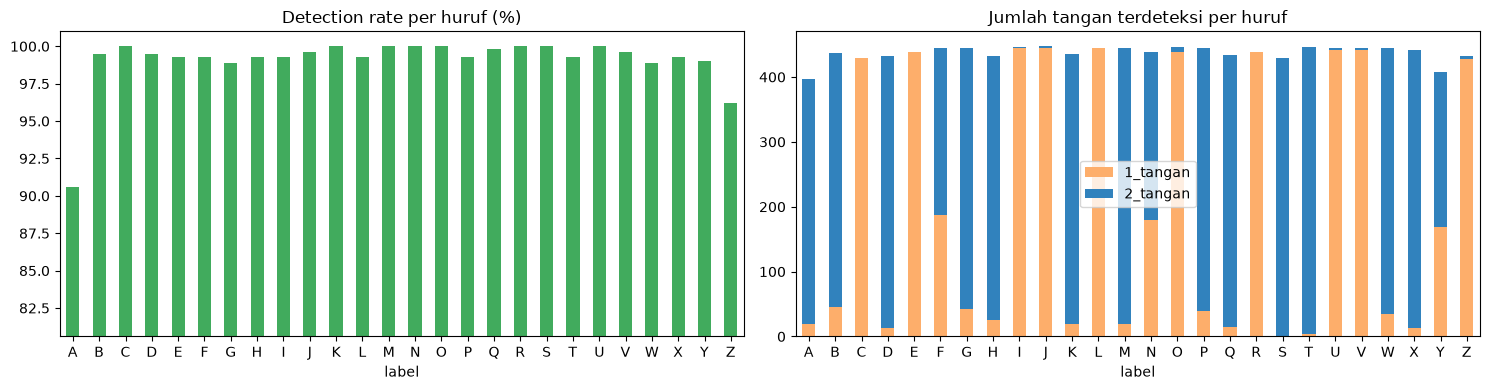

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
summary["detection_rate_%"].plot.bar(ax=axes[0], color="#41ab5d")
axes[0].set_ylim(max(0, summary["detection_rate_%"].min() - 10), 101)
axes[0].set_title("Detection rate per huruf (%)"); axes[0].tick_params(axis="x", rotation=0)
summary[["1_tangan", "2_tangan"]].plot.bar(stacked=True, ax=axes[1], color=["#fdae6b", "#3182bd"])
axes[1].set_title("Jumlah tangan terdeteksi per huruf"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Catatan:** huruf dua tangan (mis. B, D, G, K, M, S, T, X) dominan terdeteksi 2 tangan, sedangkan huruf satu tangan (C, E, I, L, O, U, V, Z) terdeteksi 1 tangan. Ini menunjukkan ekstraksi berjalan sesuai bentuk isyarat. Huruf dengan campuran 1/2 tangan perlu diperhatikan pada analisis kesalahan.

## 5. Persiapan Data: Label Encoding, Split 80:20, Scaling
- LabelEncoder mengubah huruf A–Z menjadi angka 0–25.
- train_test_split(..., stratify=y) menjaga proporsi tiap huruf sama di data latih dan uji.
- StandardScaler diletakkan di dalam Pipeline bersama classifier. Dengan begitu, di setiap fold cross-validation scaler hanya di-fit pada data latih fold tersebut, sehingga tidak ada data leakage.

In [18]:
X = df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
le = LabelEncoder().fit(df["label"].astype(str))
y = le.transform(df["label"].astype(str))
class_names = list(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"X: {X.shape} | Train: {X_train.shape[0]} | Test: {X_test.shape[0]} | Kelas: {len(class_names)}")

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

X: (11365, 126) | Train: 9092 | Test: 2273 | Kelas: 26


## 6. Training & Hyperparameter Tuning (GridSearchCV 5-fold)
Metrik pemilihan hyperparameter adalah macro F1-score, agar setiap huruf berbobot sama.

In [19]:
if QUICK_GRID:
    param_grids = {
        "SVM": [{"clf__kernel": ["rbf"], "clf__C": [1, 10], "clf__gamma": ["scale"]}],
        "RandomForest": {"clf__n_estimators": [100], "clf__max_depth": [None, 20], "clf__min_samples_split": [2]},
        "KNN": {"clf__n_neighbors": [3, 5], "clf__weights": ["distance"], "clf__metric": ["euclidean"]},
    }
else:
    param_grids = {
        "SVM": [
            {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.1, 0.01, 0.001]},
            {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10, 100]},
        ],
        "RandomForest": {"clf__n_estimators": [100, 200, 300], "clf__max_depth": [None, 10, 20, 30],
                         "clf__min_samples_split": [2, 5, 10]},
        "KNN": {"clf__n_neighbors": [1, 3, 5, 7, 9, 11], "clf__weights": ["uniform", "distance"],
                "clf__metric": ["euclidean", "manhattan", "cosine"]},
    }

estimators = {
    "SVM": SVC(random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "KNN": KNeighborsClassifier(),
}
searches, best_models, train_times = {}, {}, {}

def run_search(name):
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", estimators[name])])
    search = GridSearchCV(pipe, param_grids[name], cv=cv, scoring=SCORING, n_jobs=-1, refit=True, verbose=1)
    t0 = time.time()
    search.fit(X_train, y_train)
    train_times[name] = time.time() - t0
    searches[name], best_models[name] = search, search.best_estimator_
    print(f"Best params : {search.best_params_}")
    print(f"CV macro-F1 : {search.best_score_:.4f} ± {search.cv_results_['std_test_score'][search.best_index_]:.4f}"
          f"  ({train_times[name]:.1f} s)")
    return search

### 6.1 Support Vector Machine
SVM mencari hyperplane dengan margin maksimum. Kernel RBF memungkinkan batas keputusan non-linear. Hyperparameter C mengatur toleransi kesalahan, sedangkan gamma mengatur jangkauan pengaruh tiap sampel.

In [ ]:
run_search("SVM")
best_svm = best_models["SVM"]
n_cal = int(max(2, min(CV_FOLDS, np.bincount(y_train).min())))
best_models["SVM"] = Pipeline([
    ("scaler", clone(best_svm.named_steps["scaler"])),
    ("clf", CalibratedClassifierCV(clone(best_svm.named_steps["clf"]), method="sigmoid", cv=n_cal, ensemble=False)),
]).fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params : {'clf__C': 100, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
CV macro-F1 : 0.9769 ± 0.0031  (61.4 s)


### 6.2 Random Forest
Ensemble banyak decision tree yang dilatih pada subset data dan fitur acak, lalu hasilnya di-voting.

In [21]:
run_search("RandomForest");

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params : {'clf__max_depth': 30, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
CV macro-F1 : 0.9644 ± 0.0019  (260.0 s)


### 6.3 K-Nearest Neighbors
Klasifikasi berdasarkan mayoritas label dari k tetangga terdekat di ruang fitur.

In [22]:
run_search("KNN");

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params : {'clf__metric': 'cosine', 'clf__n_neighbors': 1, 'clf__weights': 'uniform'}
CV macro-F1 : 0.9607 ± 0.0022  (19.1 s)


In [23]:
# Pengaruh hyperparameter terhadap skor CV (top 10 kombinasi per model)
for name, s in searches.items():
    res = pd.DataFrame(s.cv_results_).sort_values("rank_test_score")
    res.to_csv(REPORTS_DIR / f"cv_results_{name}.csv", index=False)
    print(f"\n=== {name} ===")
    print(res[["params", "mean_test_score", "std_test_score", "mean_fit_time"]].head(10).to_string(index=False))


=== SVM ===
                                                      params  mean_test_score  std_test_score  mean_fit_time
{'clf__C': 100, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}         0.976943        0.003092       1.847783
   {'clf__C': 100, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}         0.976516        0.002796       2.139789
    {'clf__C': 10, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}         0.972611        0.003192       2.147928
 {'clf__C': 10, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}         0.971823        0.003178       2.297658
  {'clf__C': 100, 'clf__gamma': 0.001, 'clf__kernel': 'rbf'}         0.970714        0.001721       1.550313
                    {'clf__C': 100, 'clf__kernel': 'linear'}         0.970376        0.002522       1.438870
                     {'clf__C': 10, 'clf__kernel': 'linear'}         0.970125        0.002457       1.761444
                      {'clf__C': 1, 'clf__kernel': 'linear'}         0.967600        0.002400       1.746346
      

## 7. Evaluasi pada Data Uji

In [ ]:
results, preds = [], {}
for name, model in best_models.items():
    t0 = time.perf_counter()
    y_pred = model.predict(X_test)
    infer_ms = 1000 * (time.perf_counter() - t0) / len(X_test)
    preds[name] = y_pred
    s = searches[name]
    results.append({
        "model": name,
        "best_params": {k.replace("clf__", ""): v for k, v in s.best_params_.items()},
        "cv_f1_macro": s.best_score_,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "inference_ms_per_sample": infer_ms,
        "train_time_s": train_times[name],
    })

comparison = pd.DataFrame(results).set_index("model")
comparison.round(4).to_csv(REPORTS_DIR / "model_comparison.csv")
table = comparison.drop(columns="best_params")
try:
    import jinja2
    display(table.style.format("{:.4f}").highlight_max(
        subset=["cv_f1_macro", "accuracy", "precision_macro", "recall_macro", "f1_macro"], color="#c7e9c0"))
except ImportError:
    display(table.round(4))

,cv_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,inference_ms_per_sample,train_time_s
model,,,,,,,
SVM,0.9769,0.9828,0.9831,0.9829,0.9829,0.6114,61.4236
RandomForest,0.9644,0.9740,0.9743,0.9741,0.9740,0.1061,259.9543
KNN,0.9607,0.9710,0.9717,0.9710,0.9710,0.1938,19.1459


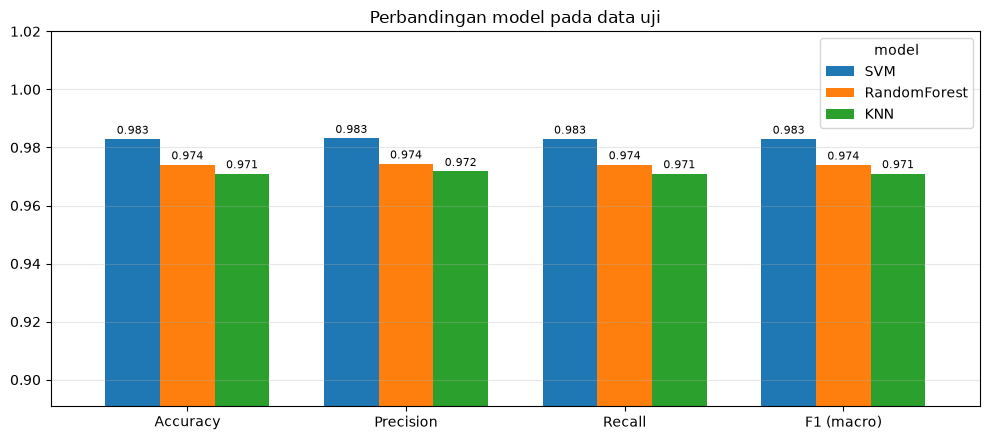

In [26]:
metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
ax = comparison[metrics].T.plot.bar(figsize=(10, 4.5), width=0.75)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylim(max(0, comparison[metrics].values.min() - 0.08), 1.02)
ax.set_xticklabels(["Accuracy", "Precision", "Recall", "F1 (macro)"], rotation=0)
ax.set_title("Perbandingan model pada data uji"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(REPORTS_DIR / "model_comparison.png", dpi=150); plt.show()

In [27]:
for name in best_models:
    report = classification_report(y_test, preds[name], labels=range(len(class_names)),
                                   target_names=class_names, digits=4, zero_division=0)
    (REPORTS_DIR / f"classification_report_{name}.txt").write_text(report, encoding="utf-8")
    print(f"========== {name} ==========\n{report}")

========== SVM ==========
              precision    recall  f1-score   support

           A     0.9634    1.0000    0.9814        79
           B     0.9457    1.0000    0.9721        87
           C     1.0000    1.0000    1.0000        86
           D     1.0000    0.9425    0.9704        87
           E     0.9885    0.9773    0.9829        88
           F     0.9886    0.9775    0.9831        89
           G     1.0000    1.0000    1.0000        89
           H     1.0000    0.9767    0.9882        86
           I     1.0000    1.0000    1.0000        89
           J     0.9889    0.9889    0.9889        90
           K     0.9886    1.0000    0.9943        87
           L     0.9457    0.9775    0.9613        89
           M     0.9348    0.9663    0.9503        89
           N     0.9759    0.9310    0.9529        87
           O     0.9888    0.9888    0.9888        89
           P     0.9775    0.9775    0.9775        89
           Q     1.0000    1.0000    1.0000        87
 

## 8. Analisis Kesalahan: Confusion Matrix
Confusion matrix ternormalisasi per baris menunjukkan persentase tiap huruf yang diprediksi sebagai huruf lain.

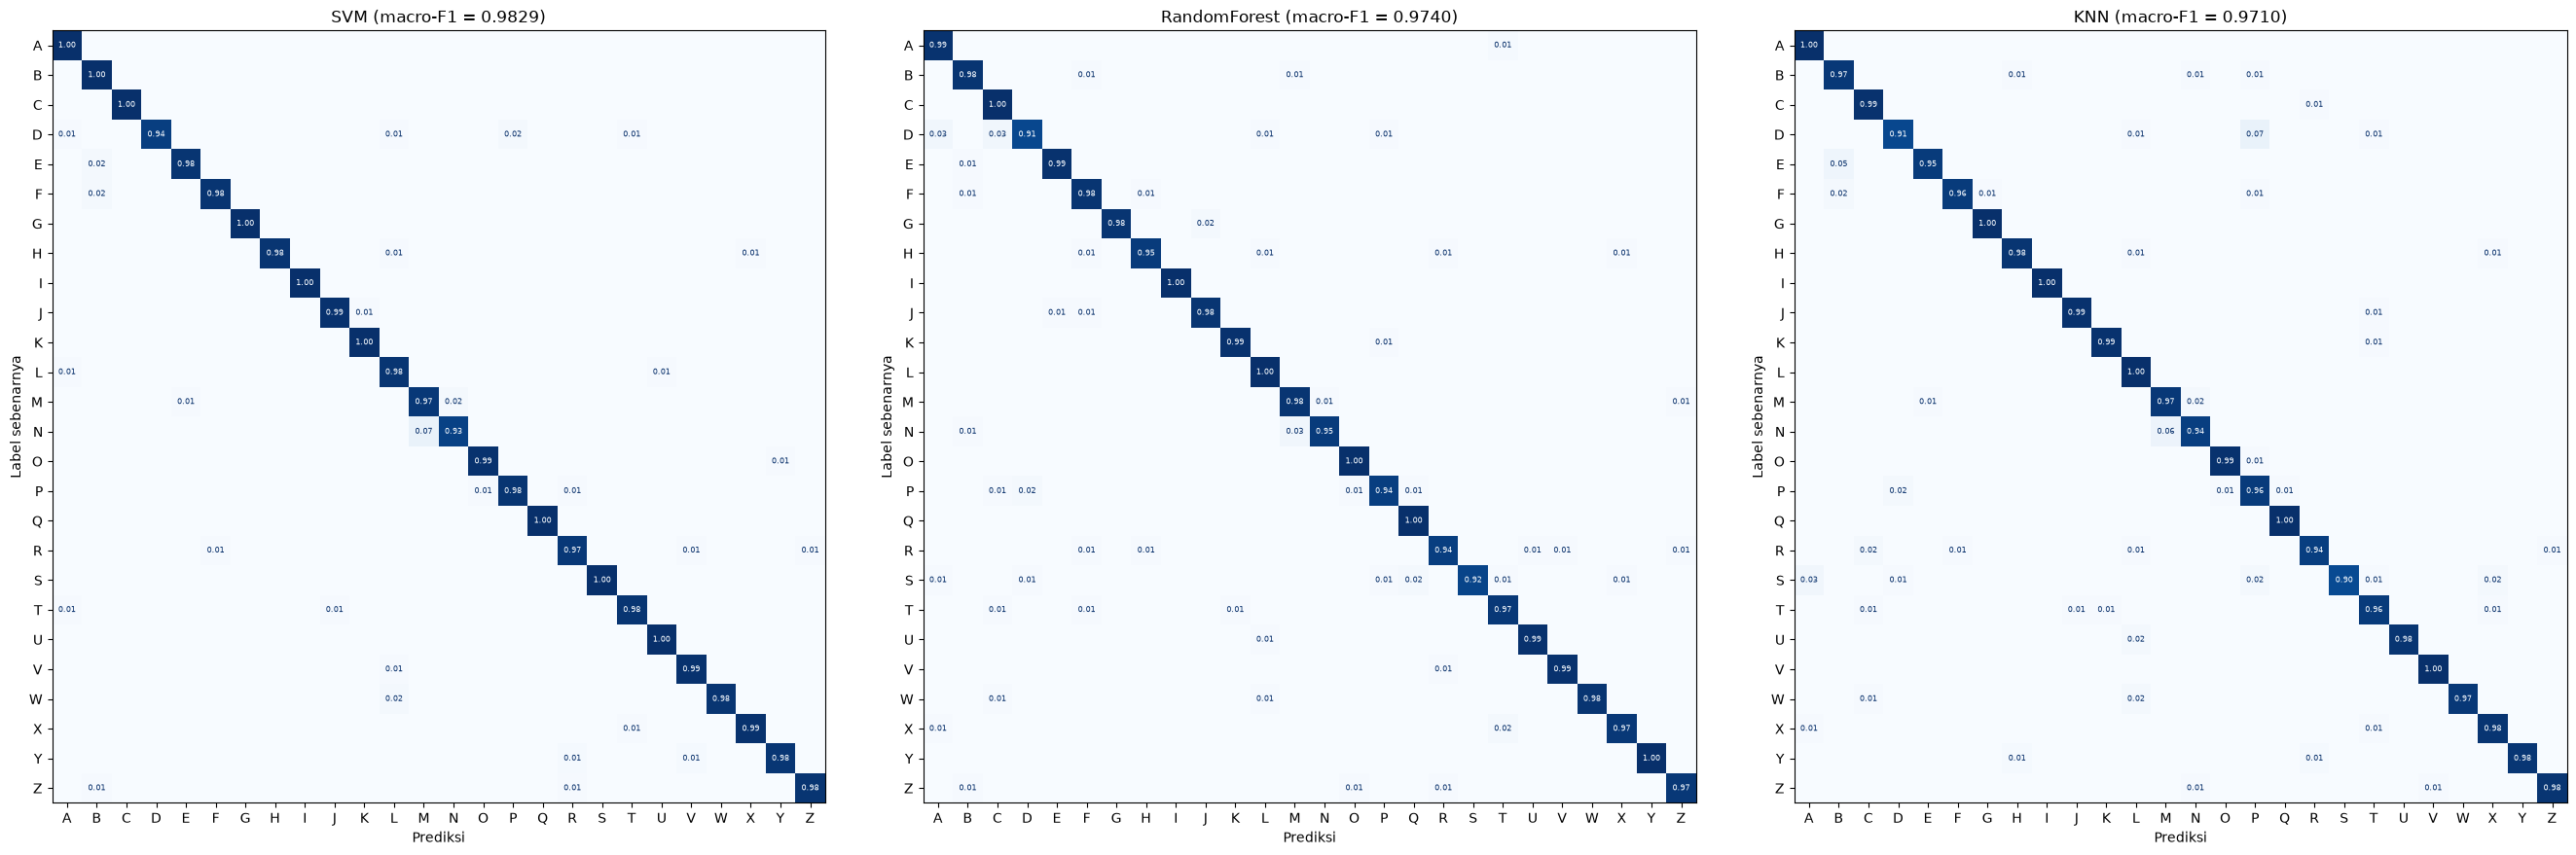

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(27, 8.5))
for ax, name in zip(axes, best_models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds[name], labels=range(len(class_names)), display_labels=class_names,
        normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    for t in ax.texts:
        t.set_fontsize(6)
        if t.get_text() == "0.00":
            t.set_text("")
    ax.set_title(f"{name} (macro-F1 = {comparison.loc[name, 'f1_macro']:.4f})")
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label sebenarnya")
plt.tight_layout(); plt.savefig(REPORTS_DIR / "confusion_matrices.png", dpi=150); plt.show()

In [29]:
def top_confusions(y_true, y_pred, k=10):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
    support = cm.sum(axis=1)
    pairs = [(class_names[i], class_names[j], int(cm[i, j]), round(100 * cm[i, j] / max(support[i], 1), 2))
             for i in range(len(class_names)) for j in range(len(class_names)) if i != j and cm[i, j] > 0]
    return (pd.DataFrame(pairs, columns=["asli", "diprediksi", "jumlah", "%_dari_kelas"])
              .sort_values("jumlah", ascending=False).head(k).reset_index(drop=True))

conf_tables = {name: top_confusions(y_test, preds[name]) for name in best_models}
for name, t in conf_tables.items():
    t.to_csv(REPORTS_DIR / f"top_confusions_{name}.csv", index=False)
pd.concat(conf_tables, axis=1)

SVM                                RandomForest                    \
  asli diprediksi jumlah %_dari_kelas         asli diprediksi jumlah   
0    N          M      6         6.90            D          C      3   
1    E          B      2         2.27            D          A      3   
2    F          B      2         2.25            N          M      3   
3    M          N      2         2.25            P          D      2   
4    D          P      2         2.30            G          J      2   
5    W          L      2         2.25            S          Q      2   
6    D          L      1         1.15            X          T      2   
7    D          T      1         1.15            A          T      1   
8    H          L      1         1.16            B          M      1   
9    J          K      1         1.11            F          B      1   

                KNN                                 
  %_dari_kelas asli diprediksi jumlah %_dari_kelas  
0         3.45    D          P      6         6.90  
1         3.45    N          M      5         5.75  
2         3.45    E          B      4         4.55  
3         2.25    S          A      3         3.49  
4         2.25    S          P      2         2.33  
5         2.33    S          X      2         2.33  
6         2.27    U          L      2         2.25  
7         1.27    R          C      2         2.27  
8         1.15    M          N      2         2.25  
9         1.12    P          D      2         2.25

In [ ]:
# Pasangan yang tertukar di lebih dari satu model -> kemiripan bentuk isyarat, bukan kelemahan algoritma
pair_counts = pd.concat([t.assign(pasangan=t["asli"] + " → " + t["diprediksi"])["pasangan"] for t in conf_tables.values()]).value_counts()
print("Pasangan yang muncul di ≥2 model:")
print(pair_counts[pair_counts >= 2].to_string())

Pasangan yang muncul di ≥2 model:
pasangan
N → M    3
E → B    2
F → B    2
M → N    2
D → P    2
P → D    2


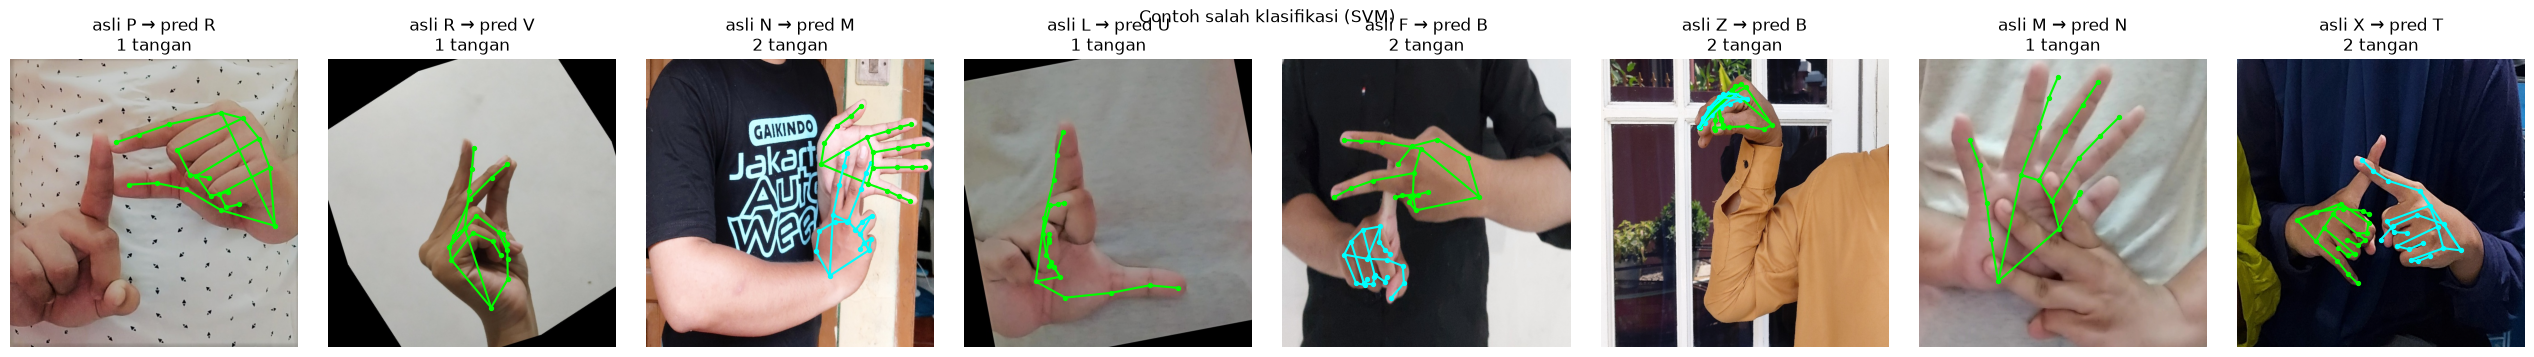

Total salah: 39 dari 2273 data uji


In [ ]:
# Visualisasi contoh salah klasifikasi dari model terbaik
best_name = comparison.sort_values(["cv_f1_macro", "f1_macro"], ascending=False).index[0]
test_paths = train_test_split(df["path"].to_numpy(), y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)[1]
wrong = np.where(preds[best_name] != y_test)[0]
n_show = min(8, len(wrong))
if n_show:
    fig, axes = plt.subplots(1, n_show, figsize=(3.2 * n_show, 3.6), squeeze=False)
    for ax, i in zip(axes[0], wrong[:n_show]):
        img = read_image(test_paths[i])
        hands, _ = detect_best(img)
        draw_hands(ax, img, hands, f"asli {class_names[y_test[i]]} → pred {class_names[preds[best_name][i]]}")
    plt.suptitle(f"Contoh salah klasifikasi ({best_name})"); plt.tight_layout(); plt.show()
print(f"Total salah: {len(wrong)} dari {len(y_test)} data uji")

Catatan: dataset berisi banyak gambar augmentasi (augmented_image_*, flip*, rotate*) yang berasal dari foto asli yang sama. Setelah digabung dan di-split acak, versi augmentasi dari satu foto bisa berada di data latih dan data uji, sehingga skor uji cenderung optimistis. Indikasinya, KNN dengan k=1 menjadi konfigurasi terbaik. Performa pada kamera real-time justru bisa saja lebih rendah.

## 9. Simpan Model Terbaik
Model dipilih berdasarkan skor CV macro-F1 (bukan skor uji) agar data uji tidak ikut mempengaruhi keputusan.

In [32]:
best_pipe = best_models[best_name]
(MODELS_DIR / "all").mkdir(exist_ok=True)
for name, m in best_models.items():
    joblib.dump(m, MODELS_DIR / "all" / f"{name}_pipeline.joblib")

joblib.dump(best_pipe.named_steps["clf"], MODELS_DIR / "best_model.joblib")
joblib.dump(best_pipe.named_steps["scaler"], MODELS_DIR / "scaler.joblib")
joblib.dump(le, MODELS_DIR / "label_encoder.joblib")
meta = {
    "best_model": best_name,
    "best_params": {k: (v if isinstance(v, (int, float, str)) or v is None else str(v))
                    for k, v in comparison.loc[best_name, "best_params"].items()},
    "cv_f1_macro": float(comparison.loc[best_name, "cv_f1_macro"]),
    "test_metrics": {m: float(comparison.loc[best_name, m]) for m in metrics},
    "classes": class_names,
    "num_features": NUM_FEATURES,
    "feature_spec": "2 tangan x 21 landmark x (x,y,z); relatif wrist, dibagi jarak maks ke wrist; "
                    "tangan diurutkan berdasarkan x wrist; zero-padding bila 1 tangan",
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "trained_at": datetime.now().isoformat(timespec="seconds"),
}
(MODELS_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Model terbaik: {best_name}")
print("Tersimpan:", *[p.name for p in sorted(MODELS_DIR.glob('*.joblib'))], "model_meta.json", sep="\n  ")

Model terbaik: SVM
Tersimpan:
  best_model.joblib
  label_encoder.joblib
  scaler.joblib
  model_meta.json


## 10. Uji Inferensi End-to-End
Simulasi alur yang sama dengan backend: muat ulang artefak dari disk > gambar > landmark > scaler > prediksi + confidence.

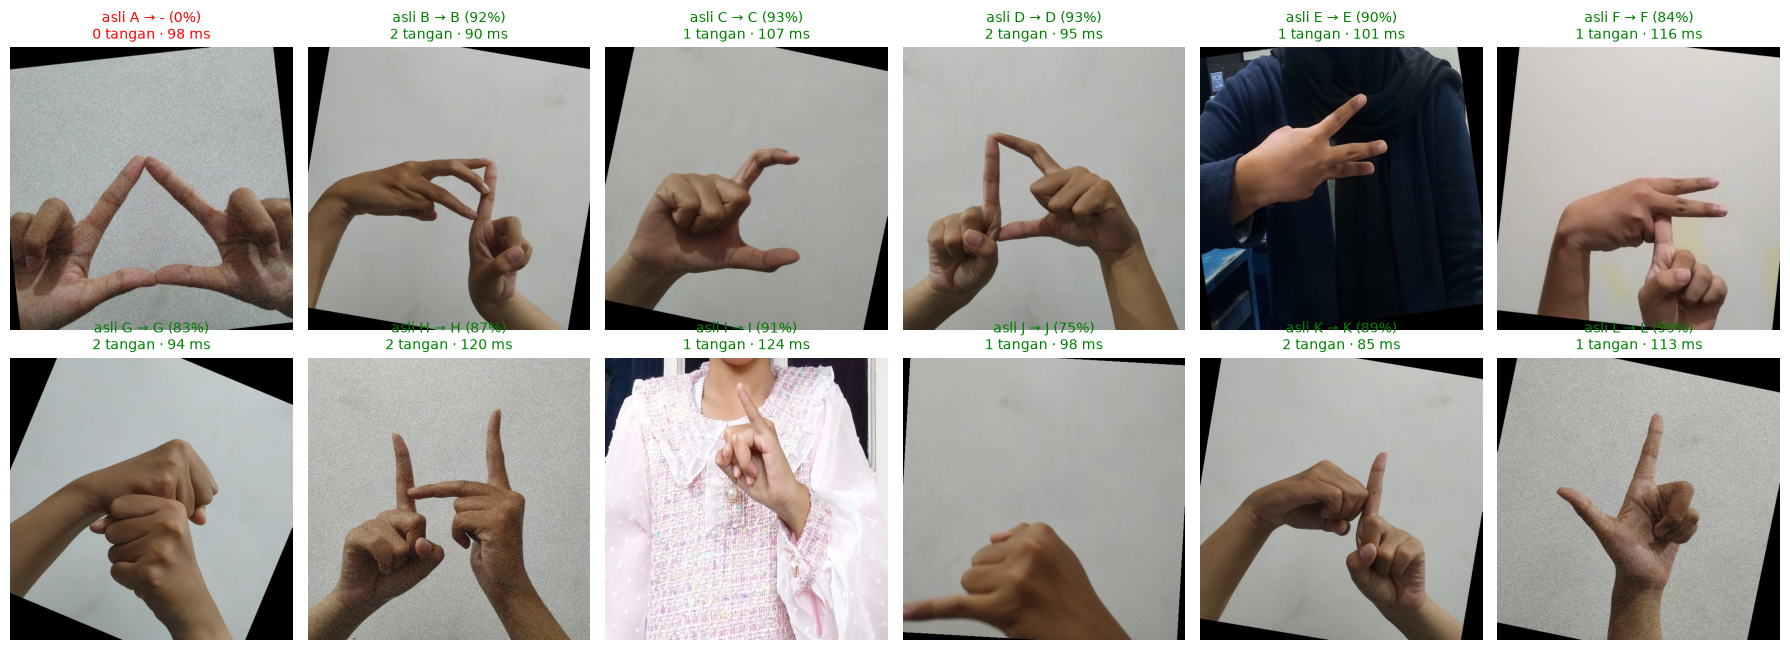

In [33]:
model = joblib.load(MODELS_DIR / "best_model.joblib")
scaler = joblib.load(MODELS_DIR / "scaler.joblib")
encoder = joblib.load(MODELS_DIR / "label_encoder.joblib")

def predict_image(image_bgr):
    feat, n_hands, _ = extract_features(image_bgr, variants=REALTIME_VARIANTS)
    if n_hands == 0:
        return None, 0.0, 0
    proba = model.predict_proba(scaler.transform(feat.reshape(1, -1)))[0]
    i = int(np.argmax(proba))
    return encoder.inverse_transform([model.classes_[i]])[0], float(proba[i]), n_hands

samples = df_files.groupby("label").sample(1, random_state=7)["path"].tolist()[:12]
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for ax, p in zip(axes.flat, samples):
    img = read_image(p)
    t0 = time.perf_counter()
    letter, conf, n = predict_image(img)
    ms = 1000 * (time.perf_counter() - t0)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ok = letter == p.parent.name
    ax.set_title(f"asli {p.parent.name} → {letter or '-'} ({conf:.0%})\n{n} tangan · {ms:.0f} ms",
                 color="green" if ok else "red", fontsize=10)
plt.tight_layout(); plt.show()

## 11. Kesimpulan

In [34]:
print(f"Data   : {summary.berhasil.sum()} sampel valid dari {summary.total.sum()} gambar "
      f"(detection rate {100 * summary.berhasil.sum() / summary.total.sum():.1f}%)")
print(f"Split  : {len(X_train)} latih / {len(X_test)} uji, 126 fitur, {len(class_names)} kelas\n")
print(comparison[["cv_f1_macro", *metrics]].round(4).to_string())
print(f"\nModel terbaik (CV macro-F1): {best_name} -> {comparison.loc[best_name, 'best_params']}")
top_pairs = pair_counts[pair_counts >= 2].index.tolist()[:5]
print("Pasangan huruf yang sering tertukar:", ", ".join(top_pairs) if top_pairs else "-")

Data   : 11365 sampel valid dari 11470 gambar (detection rate 99.1%)
Split  : 9092 latih / 2273 uji, 126 fitur, 26 kelas

              cv_f1_macro  accuracy  precision_macro  recall_macro  f1_macro
model                                                                       
SVM                0.9769    0.9828           0.9831        0.9829    0.9829
RandomForest       0.9644    0.9740           0.9743        0.9741    0.9740
KNN                0.9607    0.9710           0.9717        0.9710    0.9710

Model terbaik (CV macro-F1): SVM -> {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
Pasangan huruf yang sering tertukar: N → M, E → B, F → B, M → N, D → P


Cara menjalankan model lewat backend:
ketik uvicorn **backend.main:app --host 0.0.0.0 --port 8000** di terminal
lalu buka **http://localhost:8000** untuk klasifikasi real-time via webcam.

In [35]:
landmarker.close()